# PCA three ways: SVD vs Eigendecomposition vs Linear Autoencoder
**MA30241 Computational Linear Algebra — Course Project**
Ponna Sai Nithish (24MA10052) · Sarvesh Mahajan (24MA10060) · Sidhant Mishra (24MA10064) · Shaurya Pratap (24MA10061)

**Goal.** Compute the top-$k$ principal components of a data matrix in three ways and compare them:

| | Method | What it computes |
|---|---|---|
| 1 | **SVD** of the centred data $X_c = U\Sigma V^T$ | principal directions = first $k$ columns of $V$ |
| 2 | **Eigendecomposition** of the covariance $C = X_c^T X_c/(N-1) = Q\Lambda Q^T$ | principal directions = top-$k$ eigenvectors $Q$ |
| 3 | **Linear autoencoder** $x \to z = W_e^T x \to \hat x = W_d^T z$ trained by gradient descent | a basis $W_d$ of the principal subspace (Bourlard & Kamp, 1988) |

We compare **time, memory, reconstruction error, how close the autoencoder subspace is to the PCA subspace, and how each scales with the dimension $d$.**

Notation: $X$ is $N \times d$ ($N$ samples as rows, $d$ features), $X_c$ is $X$ with the column means subtracted, $k$ = number of components.
Runs in about a minute. Needs `numpy`, `scipy`, `matplotlib`, `pandas`, `scikit-learn` (only to load the dataset).

In [1]:
import os, time, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import subspace_angles
from sklearn.datasets import load_digits

COL  = {"SVD": "#0a9b8b", "Eig": "#e0661f", "AE": "#6250d6"}   # one colour per method in every plot
MARK = {"SVD": "o", "Eig": "s", "AE": "^"}
print("numpy", np.__version__, "| CPU cores:", os.cpu_count())

def measure(fn, repeats=3):
    # Run fn() and return (result, best wall-clock time in seconds, peak memory in MB).
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter(); out = fn(); times.append(time.perf_counter() - t0)
    tracemalloc.start()          # one extra run to record the peak memory NumPy allocates
    fn()                         # (arrays + LAPACK work buffers; the input data itself is not counted)
    peak = tracemalloc.get_traced_memory()[1] / 1e6
    tracemalloc.stop()
    return out, min(times), peak

def rel_error(Xc, Xhat):         # relative reconstruction error  ||Xc - Xhat||_F / ||Xc||_F
    return np.linalg.norm(Xc - Xhat) / np.linalg.norm(Xc)

def max_angle(A, B):             # largest principal angle (degrees) between span(A) and span(B)
    return np.degrees(subspace_angles(A, B)).max()

numpy 2.5.3 | CPU cores: 2


## 1. The three methods

**Why 1 and 2 give the same answer.** If $X_c = U\Sigma V^T$ then
$C = \frac{1}{N-1}X_c^T X_c = V\,\frac{\Sigma^2}{N-1}\,V^T$, so the eigenvectors of $C$ are the right singular vectors of $X_c$ and $\lambda_i = \sigma_i^2/(N-1)$.

**Why 3 gives the same subspace.** The autoencoder minimises $\|X_c - X_c W_e W_d\|_F^2$, i.e. it looks for the best rank-$k$ approximation of $X_c$.
By Eckart–Young that is $X_c V_k V_k^T$. Bourlard & Kamp (1988) show the optimal weights are $W_d^T = V_k T^{-1}$, $W_e = V_k T^T$ for **any** invertible $k\times k$ matrix $T$:
same subspace, but the basis is not orthonormal and not ordered by variance.

In [2]:
def pca_svd(Xc, k):
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)      # Xc = U Σ Vᵀ   (thin SVD)
    return Vt[:k].T, S[:k]**2 / (len(Xc) - 1)              # top-k directions (d×k), variances

def pca_eig(Xc, k):
    C = Xc.T @ Xc / (len(Xc) - 1)                          # d×d covariance matrix
    lam, Q = np.linalg.eigh(C)                             # symmetric eigensolver (ascending order)
    return Q[:, ::-1][:, :k], lam[::-1][:k]                # flip to descending, keep top k

def pca_autoencoder(Xc, k, epochs=100, batch=32, lr=(0.05, 3e-4), seed=0):
    # Linear autoencoder: z = x·We (k hidden units, no activation), x_hat = z·Wd.
    # Loss = mean over the mini-batch of ||x_hat - x||².  Trained with mini-batch Adam.
    rng = np.random.default_rng(seed)
    N, d = Xc.shape
    We = rng.normal(0, 1 / np.sqrt(d), (d, k))             # encoder weights  d×k
    Wd = rng.normal(0, 1 / np.sqrt(k), (k, d))             # decoder weights  k×d
    params = [We, Wd]
    m = [np.zeros_like(p) for p in params]                 # Adam first moments
    v = [np.zeros_like(p) for p in params]                 # Adam second moments
    step = 0
    for ep in range(epochs):
        lr_ep = lr[0] * (lr[1] / lr[0]) ** (ep / (epochs - 1))   # learning rate decays from lr[0] to lr[1]
        perm = rng.permutation(N)
        for i in range(0, N, batch):
            xb = Xc[perm[i:i + batch]]
            Z = xb @ We                                    # forward: hidden layer
            R = Z @ Wd - xb                                # forward: reconstruction error x_hat - x
            g_Wd = 2 / len(xb) * Z.T @ R                   # backprop: dLoss/dWd
            g_We = 2 / len(xb) * xb.T @ (R @ Wd.T)         # backprop: dLoss/dWe
            step += 1
            for p, g, mi, vi in zip(params, (g_We, g_Wd), m, v):     # Adam update (in place)
                mi[:] = 0.9 * mi + 0.1 * g
                vi[:] = 0.999 * vi + 0.001 * g**2
                p -= lr_ep * (mi / (1 - 0.9**step)) / (np.sqrt(vi / (1 - 0.999**step)) + 1e-8)
    return We, Wd

## 2. Dataset 1 — handwritten digits (real data)
`sklearn`'s **digits** dataset: 1797 grey-scale images of handwritten digits 0–9, each $8\times8$ pixels, so each image is a vector of 64 numbers (pixel intensity 0–16, scaled here to 0–1).
3 pixels are blank in every image (zero variance, no information) and are dropped, so $N = 1797,\ d = 61$.
We centre the data once; all three methods use the same $X_c$.

N = 1797 images, d = 61 pixels


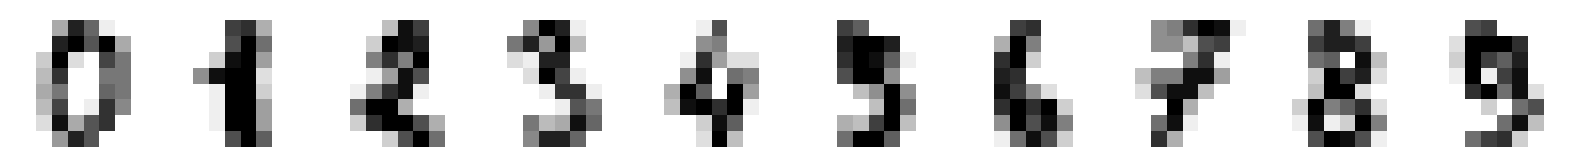

k = 21 components keep 90.3% of the variance


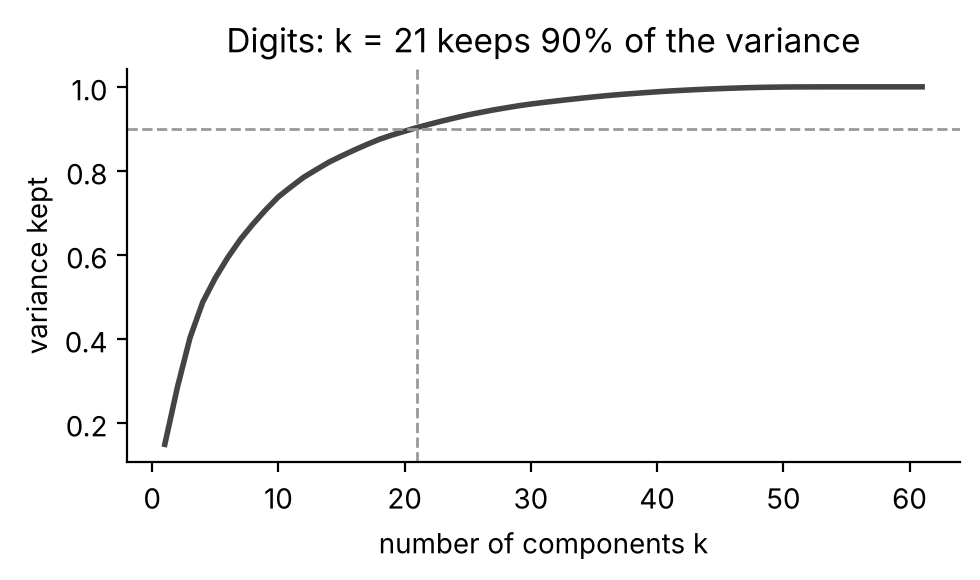

In [3]:
digits = load_digits()
keep = digits.data.std(axis=0) > 0                 # drop the 3 always-blank pixels
X = digits.data[:, keep] / 16.0
mean = X.mean(axis=0)
Xc = X - mean                                      # centred data, N×d
N, d = Xc.shape
print(f"N = {N} images, d = {d} pixels")

fig, axes = plt.subplots(1, 10, figsize=(8, 1.1))          # one example of each digit
for dgt in range(10):
    axes[dgt].imshow(digits.images[np.argmax(digits.target == dgt)], cmap="gray_r")
    axes[dgt].axis("off")
plt.tight_layout(); plt.savefig("fig_digits_samples.png", dpi=200); plt.show()

# Choose k: smallest k that keeps at least 90% of the variance (sum of sigma_i^2)
S_all = np.linalg.svd(Xc, compute_uv=False)
energy = np.cumsum(S_all**2) / np.sum(S_all**2)
k = int(np.argmax(energy >= 0.90)) + 1
print(f"k = {k} components keep {energy[k-1]:.1%} of the variance")

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(np.arange(1, d + 1), energy, color="#444", lw=2)
ax.axhline(0.9, color="#999", ls="--", lw=1); ax.axvline(k, color="#999", ls="--", lw=1)
ax.set_xlabel("number of components k"); ax.set_ylabel("variance kept")
ax.set_title(f"Digits: k = {k} keeps 90% of the variance")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("fig_variance.png", dpi=200); plt.show()

## 3. Run all three methods on the digits

In [4]:
(V_svd, lam_svd), t_svd, m_svd = measure(lambda: pca_svd(Xc, k), repeats=5)
(V_eig, lam_eig), t_eig, m_eig = measure(lambda: pca_eig(Xc, k), repeats=5)
(We, Wd),         t_ae,  m_ae  = measure(lambda: pca_autoencoder(Xc, k), repeats=1)

recon = {"SVD": Xc @ V_svd @ V_svd.T,               # project onto the subspace and back
         "Eig": Xc @ V_eig @ V_eig.T,
         "AE":  Xc @ We @ Wd}
best = np.sqrt(np.sum(S_all[k:]**2)) / np.linalg.norm(Xc)   # Eckart–Young: smallest possible error

table = pd.DataFrame({
    "time (ms)":            [1e3 * t_svd, 1e3 * t_eig, 1e3 * t_ae],
    "peak memory (MB)":     [m_svd, m_eig, m_ae],
    "relative recon. error": [rel_error(Xc, recon[m]) for m in recon],
    "max angle to SVD subspace (deg)": [0.0, max_angle(V_eig, V_svd), max_angle(Wd.T, V_svd)],
}, index=["SVD", "Eig", "AE"])
print(f"Best possible relative error with k = {k} (Eckart–Young): {best:.6f}")
table.round(4)

Best possible relative error with k = 21 (Eckart–Young): 0.311129


,time (ms),peak memory (MB),relative recon. error,max angle to SVD subspace (deg)
SVD,5.5072,2.8194,0.3111,0.0000
Eig,0.8478,0.1567,0.3111,0.0000
AE,525.9661,0.1781,0.3111,0.9759


### Checks
* SVD and eigendecomposition must agree: same variances $\lambda_i=\sigma_i^2/(N-1)$, same subspace.
* The autoencoder must reach (almost) the Eckart–Young error and its decoder must span (almost) the same subspace.
* But the autoencoder basis is **not orthonormal**: $W_d W_d^T \neq I$.

In [5]:
print("max |λ_eig - λ_svd| / λ_svd       :", np.max(np.abs(lam_eig - lam_svd) / lam_svd))
print("angle SVD vs Eig subspace (deg)   :", max_angle(V_eig, V_svd))
ang = np.degrees(subspace_angles(Wd.T, V_svd))
print(f"AE decoder vs PCA: max angle {ang.max():.2f}°, mean {ang.mean():.2f}°")
print(f"AE encoder vs PCA: max angle {max_angle(We, V_svd):.2f}°")
print(f"AE error is {100 * (rel_error(Xc, recon['AE']) / best - 1):.4f}% above the optimum")
G = Wd @ Wd.T
print(f"diag(Wd Wdᵀ) ranges {G.diagonal().min():.2f} to {G.diagonal().max():.2f} (would be 1 if orthonormal); "
      f"largest off-diagonal {np.abs(G - np.diag(G.diagonal())).max():.2f} (would be 0)")

assert max_angle(V_eig, V_svd) < 1e-6 and np.allclose(lam_eig, lam_svd)
assert rel_error(Xc, recon["AE"]) < 1.001 * best and ang.max() < 2

max |λ_eig - λ_svd| / λ_svd       : 3.426469702408351e-15
angle SVD vs Eig subspace (deg)   : 9.756094890469867e-13
AE decoder vs PCA: max angle 0.98°, mean 0.23°
AE encoder vs PCA: max angle 1.54°
AE error is 0.0045% above the optimum
diag(Wd Wdᵀ) ranges 5.47 to 9.24 (would be 1 if orthonormal); largest off-diagonal 1.37 (would be 0)


### What the reconstructions and the basis vectors look like
Top: the same 8 digits reconstructed from $k$ numbers each — all three methods look identical.
Bottom: the first 8 PCA directions vs the first 8 autoencoder decoder vectors — **different basis, same subspace**.

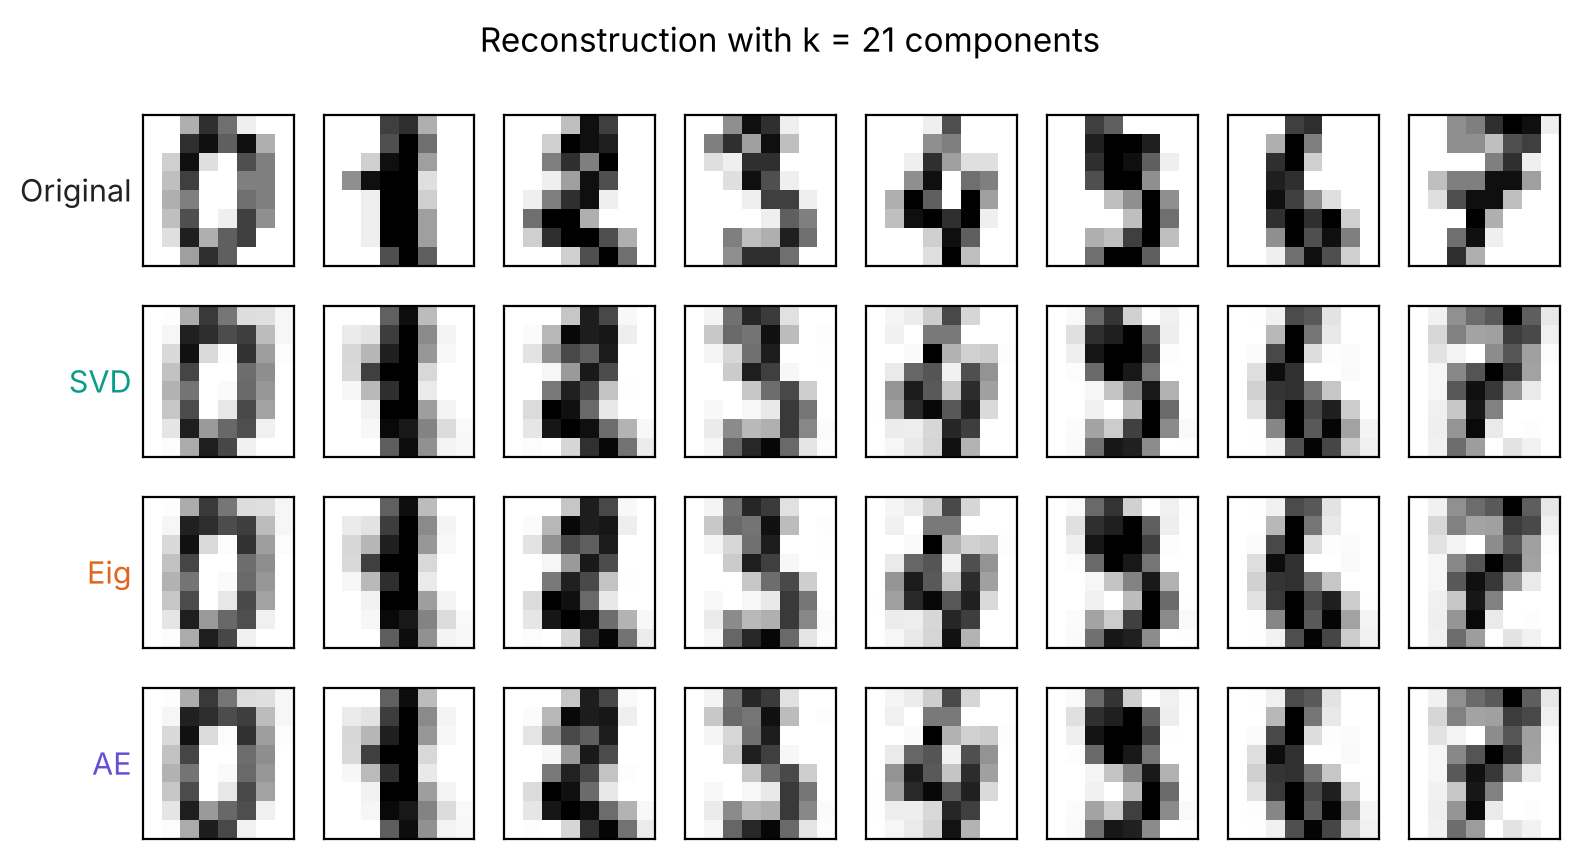

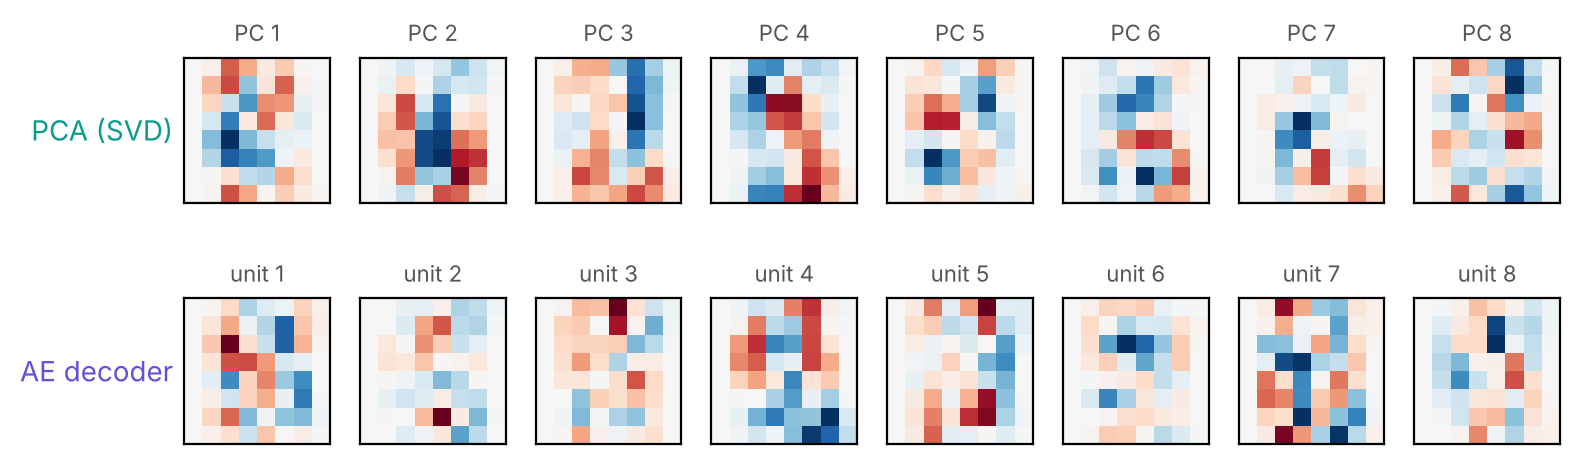

In [6]:
def to_img(v):                                   # put the 3 dropped pixels back (as 0) and reshape to 8×8
    full = np.zeros(64); full[keep] = v
    return full.reshape(8, 8)

idx = np.arange(8)
rows = [("Original", Xc)] + [(name, recon[name]) for name in ["SVD", "Eig", "AE"]]
fig, axes = plt.subplots(4, 8, figsize=(8, 4.4))
for r, (name, M) in enumerate(rows):
    for c, i in enumerate(idx):
        axes[r, c].imshow(to_img(M[i] + mean), cmap="gray_r", vmin=0, vmax=1)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=11,
                          color=COL.get(name, "#222"))
plt.suptitle(f"Reconstruction with k = {k} components", fontsize=12)
plt.tight_layout(); plt.savefig("fig_reconstructions.png", dpi=200); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(8, 2.7))
for c in range(8):
    for r, (name, vec) in enumerate([("PCA (SVD)", V_svd[:, c]), ("AE decoder", Wd[c])]):
        lim = np.abs(vec).max()
        axes[r, c].imshow(to_img(vec), cmap="RdBu_r", vmin=-lim, vmax=lim)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        axes[r, c].set_title(f"PC {c+1}" if r == 0 else f"unit {c+1}", fontsize=8, color="#555")
        if c == 0:
            axes[r, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10,
                                  color=COL["SVD"] if r == 0 else COL["AE"])
plt.tight_layout(); plt.savefig("fig_basis.png", dpi=200); plt.show()

## 4. Dataset 2 — synthetic data of growing dimension (scalability)
To see how each method scales, we generate data whose dimension $d$ we control: $N = 2000$ samples in $d$ dimensions that truly lie near a **10-dimensional** subspace
(10 hidden factors with standard deviations 3 → 1, plus small noise of std 0.1). So the right answer is $k = 10$, and we vary $d$ from 50 to 1600.

Expected cost ($N \ge d$): SVD $O(Nd^2)$ · Eig $O(Nd^2 + d^3)$ (forming $C$ + eigensolver) · Autoencoder $O(E \cdot N d k)$ for $E$ epochs.

In [7]:
def make_data(N, d, seed=0):
    rng = np.random.default_rng(seed)
    A, _ = np.linalg.qr(rng.normal(size=(d, 10)))          # 10 orthonormal hidden directions in R^d
    Z = rng.normal(size=(N, 10)) * np.linspace(3, 1, 10)   # hidden factors with std 3, ..., 1
    return Z @ A.T + 0.1 * rng.normal(size=(N, d))         # + small noise in every direction

rows = []
for dd in [50, 100, 200, 400, 800, 1600]:
    Xs = make_data(2000, dd); Xs -= Xs.mean(axis=0)
    (Vs, _), ts, ms   = measure(lambda: pca_svd(Xs, 10))
    (Ve, _), te, me   = measure(lambda: pca_eig(Xs, 10))
    (Ae, Ad), ta, ma  = measure(lambda: pca_autoencoder(Xs, 10), repeats=2)
    rows.append({"d": dd, "SVD time (s)": ts, "Eig time (s)": te, "AE time (s)": ta,
                 "SVD mem (MB)": ms, "Eig mem (MB)": me, "AE mem (MB)": ma,
                 "Eig angle (deg)": max_angle(Ve, Vs), "AE angle (deg)": max_angle(Ad.T, Vs)})
    print(f"d = {dd} done")
scal = pd.DataFrame(rows).set_index("d")
scal.round(4)

d = 50 done


d = 100 done


d = 200 done


d = 400 done


d = 800 done


d = 1600 done


,SVD time (s),Eig time (s),AE time (s),SVD mem (MB),Eig mem (MB),AE mem (MB),Eig angle (deg),AE angle (deg)
d,,,,,,,,
50,0.0039,0.0007,0.3037,2.5285,0.1067,0.1048,0.0,0.1039
100,0.0103,0.0014,0.3948,5.2953,0.4119,0.1886,0.0,0.1239
200,0.0259,0.0047,0.5203,11.5489,1.6223,0.3543,0.0,0.1382
400,0.0949,0.0204,0.8252,26.9361,6.4431,0.6872,0.0,0.2152
800,0.4230,0.1233,1.5822,69.2315,25.6847,1.3528,0.0,0.2723
1600,2.2832,0.7921,3.1816,179.4194,102.5690,2.5343,0.0,1.8112


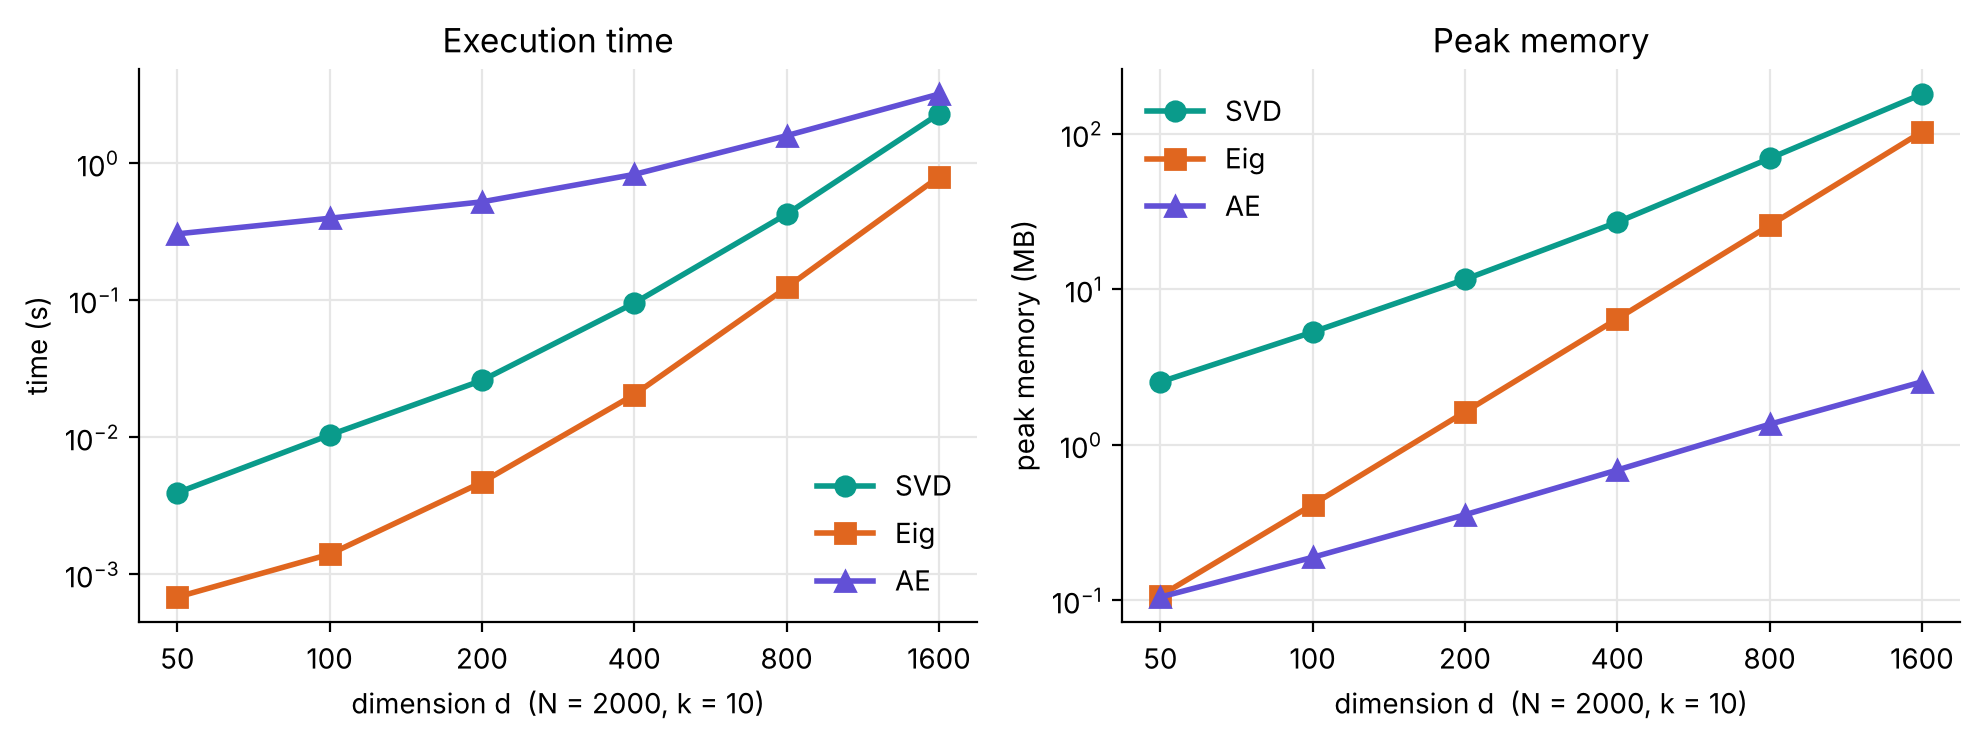

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, what, unit in [(axes[0], "time", "s"), (axes[1], "mem", "MB")]:
    for mth in ["SVD", "Eig", "AE"]:
        y = scal[f"{mth} {what} ({unit})"]
        ax.plot(scal.index, y, marker=MARK[mth], color=COL[mth], lw=2, ms=7, label=mth)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks(scal.index, [str(v) for v in scal.index]); ax.minorticks_off()
    ax.set_xlabel("dimension d  (N = 2000, k = 10)")
    ax.set_ylabel("time (s)" if what == "time" else "peak memory (MB)")
    ax.grid(True, which="major", color="#e6e6e6", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_title("Execution time"); axes[1].set_title("Peak memory")
axes[0].legend(frameon=False); axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("fig_scaling.png", dpi=200); plt.show()

In [9]:
# Empirical growth rate for large d: fit  cost ∝ d^p  over d = 400 ... 1600 (slope on the log-log plot)
big = scal.loc[400:]
for mth in ["SVD", "Eig", "AE"]:
    p_time = np.polyfit(np.log(big.index), np.log(big[f"{mth} time (s)"]), 1)[0]
    p_mem  = np.polyfit(np.log(big.index), np.log(big[f"{mth} mem (MB)"]), 1)[0]
    print(f"{mth}: time ∝ d^{p_time:.1f}   memory ∝ d^{p_mem:.1f}")

SVD: time ∝ d^2.3   memory ∝ d^1.4
Eig: time ∝ d^2.6   memory ∝ d^2.0
AE: time ∝ d^1.0   memory ∝ d^0.9


## 5. Numerical accuracy: SVD vs eigendecomposition
Forming $X^TX$ squares the condition number: $\kappa(X^TX)=\kappa(X)^2$. Directions with $\sigma_i/\sigma_1$ below $\sqrt{\varepsilon_{\text{mach}}}\approx 10^{-8}$ are lost.
Classic example (Läuchli matrix) with $\varepsilon = 10^{-8}$: in floating point $1+\varepsilon^2 = 1$, so $X^TX$ becomes the all-ones matrix (rank 1).

In [10]:
eps = 1e-8
A = np.array([[1, 1, 1], [eps, 0, 0], [0, eps, 0], [0, 0, eps]])
true  = np.array([np.sqrt(3 + eps**2), eps, eps])                 # exact singular values
s_svd = np.linalg.svd(A, compute_uv=False)                        # SVD works on A directly
s_eig = np.sqrt(np.clip(np.linalg.eigvalsh(A.T @ A)[::-1], 0, None))   # sqrt of eigenvalues of AᵀA
pd.DataFrame({"exact σ": true, "SVD": s_svd, "sqrt(eig of AᵀA)": s_eig,
              "SVD rel. error": np.abs(s_svd - true) / true,
              "Eig rel. error": np.abs(s_eig - true) / true}, index=["σ1", "σ2", "σ3"])

,exact σ,SVD,sqrt(eig of AᵀA),SVD rel. error,Eig rel. error
σ1,1.732051e+00,1.732051e+00,1.732051,0.000000e+00,0.0
σ2,1.000000e-08,1.000000e-08,0.000000,0.000000e+00,1.0
σ3,1.000000e-08,1.000000e-08,0.000000,4.963084e-16,1.0


## 6. Summary
* **SVD and eigendecomposition give the same principal components** (angle ≈ 0, identical variances). Eig is faster when $N \gg d$ because $X^TX$ is one fast matrix product and the eigenproblem is only $d\times d$; SVD keeps the $N\times d$ factor $U$, so it uses more memory, but it is the numerically safer choice (no squaring of $\kappa$).
* **The linear autoencoder learns the same subspace** (largest principal angle about 1° on the digits, error within 0.01% of the Eckart–Young optimum), exactly as Bourlard & Kamp predict, but its basis is **not orthonormal or ordered**, it needs a learning rate and many epochs, and it is much slower at these sizes.
* Its advantages: tiny memory ($O(dk)$ weights + one mini-batch), works on streaming data, and it extends to non-linear (deep) autoencoders.